# **Tensorflow Regression Project**

### **Introduction**

The **EV Energy Consumption Dataset** contains operational and environmental data related to electric vehicles (EVs), including features such as battery capacity, battery health, state of charge (SOC), vehicle speed, acceleration, road gradient, ambient temperature, tire pressure, HVAC usage, traffic conditions, passenger count, driving mode, and other vehicle-related parameters. The dataset is designed to analyze the factors influencing electric vehicle energy consumption and is widely used for energy analysis, predictive modeling, and machine learning applications in the electric mobility domain.

In this project, **Exploratory Data Analysis (EDA)** is performed using Python libraries such as **Pandas, NumPy, Matplotlib, and Seaborn** to understand the dataset's structure, identify patterns, detect outliers, examine feature distributions, and analyze the relationships between different variables. Various visualizations are used to study the impact of driving conditions, environmental factors, and vehicle characteristics on energy consumption.

Furthermore, **TensorFlow-based Deep Learning Regression** is applied to predict the energy consumption of electric vehicles based on the available input features. Data preprocessing techniques, including duplicate removal, feature engineering, categorical encoding, and feature scaling, are carried out to improve model performance. The trained regression model learns the relationship between the input variables and the target variable, **Energy_Consumption_kWh**, enabling accurate prediction of energy usage under different driving scenarios.

The main objective of this project is to gain meaningful insights into the factors affecting electric vehicle energy consumption and to develop a reliable regression model capable of accurately predicting energy usage. The project demonstrates the complete machine learning workflow, including data preprocessing, exploratory data analysis, feature engineering, TensorFlow model development, performance evaluation using **MAE, MSE, RMSE, and R² Score**, and visualization of prediction results.


### **Import Necessary Libraries**

In [1]:
#remove warning messages
import warnings
warnings.filterwarnings('ignore')

#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

### **Import Dataset**

In [2]:
df = pd.read_csv("EV_Energy_Consumption_Dataset_1.csv")

### **Display the first 5 rows**

In [3]:
df.head(2)

,Vehicle_ID,Timestamp,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
0,1102,1/1/2024 0:00,111.507366,-2.773816,30.415148,378.091525,25.314786,Sport,Highway,Low,6.879446,Fog,0.741770,42.172533,7.829253,31.112020,1822.967368,20.757508,12.054317
1,1435,1/1/2024 0:01,48.612323,-0.796982,97.385534,392.718377,18.240755,Eco,Urban,Low,-3.007212,Fog,-3.495516,57.018427,4.495572,31.504366,2091.831914,0.642918,4.488701


### **Dispaly the last 5 rows**

In [4]:
df.tail(2)

,Vehicle_ID,Timestamp,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
4998,1903,1/4/2024 11:18,6.618791,-2.642843,91.904887,302.708366,31.781034,Sport,Highway,Medium,-3.366394,Snow,16.154754,74.929797,13.503355,33.363985,1274.506744,32.768008,5.581431
4999,1214,1/4/2024 11:19,98.476987,0.489050,82.716863,308.334933,24.703606,Eco,Highway,Low,-2.129397,Fog,29.660221,41.293694,0.359335,31.152982,1837.999134,12.633833,7.841474


### **Data Cleaning**

In [5]:
#Convert column name to standard type

df.columns = (df.columns
              .str.strip()
              .str.title()
              .str.replace(" ","_")
              .str.replace("-","_")
              .str.replace("%","")
              .str.rstrip('_')
              )

In [6]:
#Convert date columns to date format

df["Timestamp"] = pd.to_datetime(df["Timestamp"])

In [7]:
#Check whether there is missing values

print(df.isnull().sum())

Vehicle_Id                0
Timestamp                 0
Speed_Kmh                 0
Acceleration_Ms2          0
Battery_State             0
Battery_Voltage_V         0
Battery_Temperature_C     0
Driving_Mode              0
Road_Type                 0
Traffic_Condition         0
Slope                     0
Weather_Condition         0
Temperature_C             0
Humidity                  0
Wind_Speed_Ms             0
Tire_Pressure_Psi         0
Vehicle_Weight_Kg         0
Distance_Travelled_Km     0
Energy_Consumption_Kwh    0
dtype: int64


In [8]:
#Check for duplicate values
df.duplicated().sum()

0

### **Data Understanding**

In [9]:
#Basic Information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Vehicle_Id              5000 non-null   int64         
 1   Timestamp               5000 non-null   datetime64[ns]
 2   Speed_Kmh               5000 non-null   float64       
 3   Acceleration_Ms2        5000 non-null   float64       
 4   Battery_State           5000 non-null   float64       
 5   Battery_Voltage_V       5000 non-null   float64       
 6   Battery_Temperature_C   5000 non-null   float64       
 7   Driving_Mode            5000 non-null   object        
 8   Road_Type               5000 non-null   object        
 9   Traffic_Condition       5000 non-null   object        
 10  Slope                   5000 non-null   float64       
 11  Weather_Condition       5000 non-null   object        
 12  Temperature_C           5000 non-null   float64 

In [10]:
# Use summary statistics to understand distribution
df.describe()

,Vehicle_Id,Speed_Kmh,Acceleration_Ms2,Battery_State,Battery_Voltage_V,Battery_Temperature_C,Slope,Temperature_C,Humidity,Wind_Speed_Ms,Tire_Pressure_Psi,Vehicle_Weight_Kg,Distance_Travelled_Km,Energy_Consumption_Kwh
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,1505.701200,59.312952,-0.019885,60.214465,351.118306,27.510130,2.504690,17.312654,55.302173,7.505087,31.503390,1854.719760,24.994042,8.437983
std,290.836902,34.517605,1.724287,23.128262,28.968372,10.015385,4.360854,13.005106,20.161289,4.325455,2.017357,373.685150,14.246454,2.184809
min,1000.000000,0.001396,-2.999683,20.020196,300.004812,10.003858,-4.991079,-4.995288,20.027119,0.000126,28.001891,1200.960317,0.107544,1.881426
25%,1253.000000,29.515400,-1.490240,40.088318,326.613439,18.884742,-1.235653,5.950476,37.970900,3.837738,29.772709,1531.417633,12.736568,6.771081
50%,1510.000000,58.646794,-0.043329,60.490283,351.510915,27.581710,2.452368,17.330798,55.650512,7.495373,31.484048,1865.006523,24.640458,8.455746
75%,1761.000000,89.030001,1.473887,80.409928,375.968140,35.920162,6.366990,28.624021,72.650838,11.291284,33.256528,2181.071491,37.562482,10.031938
max,1999.000000,119.946924,2.998039,99.993986,399.990098,44.985943,9.998358,39.998063,89.988891,14.999095,34.997829,2499.504564,49.993767,14.660528


## **Data Analysis and Visualization**

In [11]:
df_plot = df.sample(n=500, random_state=42)

In [11]:
df.columns

Index(['Vehicle_Id', 'Timestamp', 'Speed_Kmh', 'Acceleration_Ms2',
       'Battery_State', 'Battery_Voltage_V', 'Battery_Temperature_C',
       'Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Slope',
       'Weather_Condition', 'Temperature_C', 'Humidity', 'Wind_Speed_Ms',
       'Tire_Pressure_Psi', 'Vehicle_Weight_Kg', 'Distance_Travelled_Km',
       'Energy_Consumption_Kwh'],
      dtype='object')

1. What Does the dataset contain

In [12]:
print("Number of Rows: ", df.shape[0])
print("Number of Columns: ", df.shape[1])

print("\nNumber of Unique Vehicles:")
print(df["Vehicle_Id"].nunique())


Number of Rows:  5000
Number of Columns:  19

Number of Unique Vehicles:
989


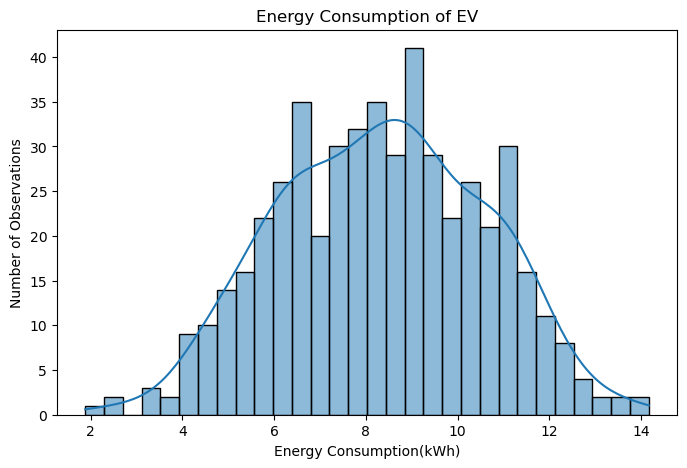

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(df_plot["Energy_Consumption_Kwh"], bins=30, kde=True)

plt.title("Energy Consumption of EV")
plt.xlabel("Energy Consumption(kWh)")
plt.ylabel("Number of Observations")
plt.show()

This graph shows how energy consumtion varies accross all 5000 observations

2. Does Driving Speed affect Energy Consumption?

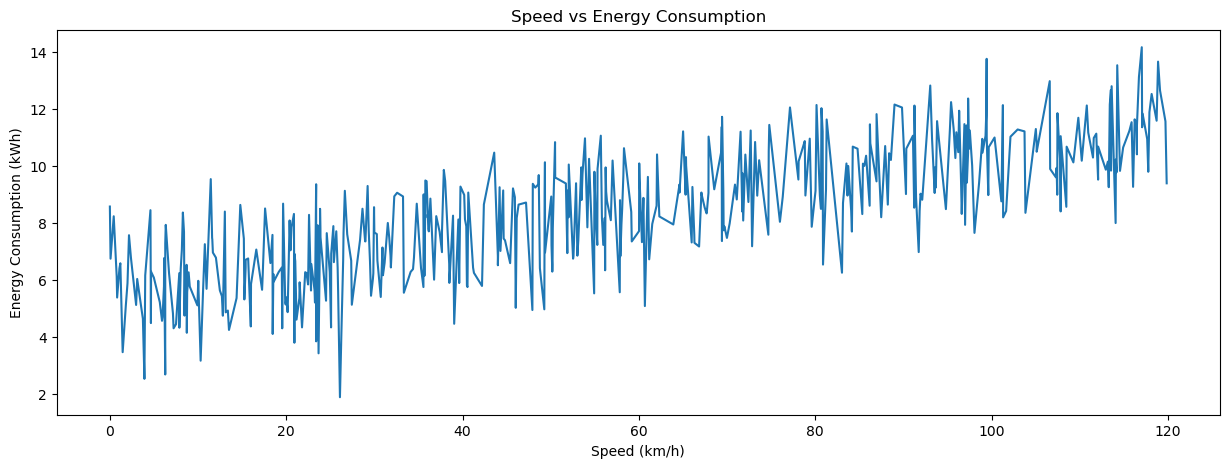

In [12]:
plt.figure(figsize=(15,5))

speed = df_plot["Speed_Kmh"].sort_values()
sns.lineplot(data=df, x=speed, y="Energy_Consumption_Kwh")

plt.title("Speed vs Energy Consumption")
plt.xlabel("Speed (km/h)")
plt.ylabel("Energy Consumption (kWh)")
plt.show()

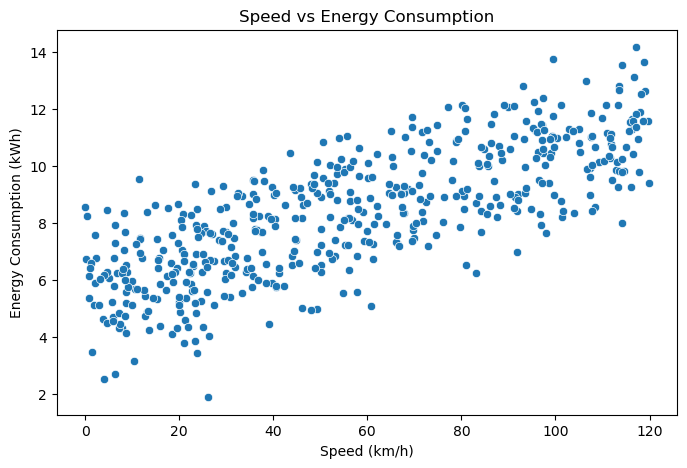

In [13]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df_plot, x="Speed_Kmh", y="Energy_Consumption_Kwh")

plt.title("Speed vs Energy Consumption")
plt.xlabel("Speed (km/h)")
plt.ylabel("Energy Consumption (kWh)")
plt.show()

Do road and traffic conditions affect energy consumption?

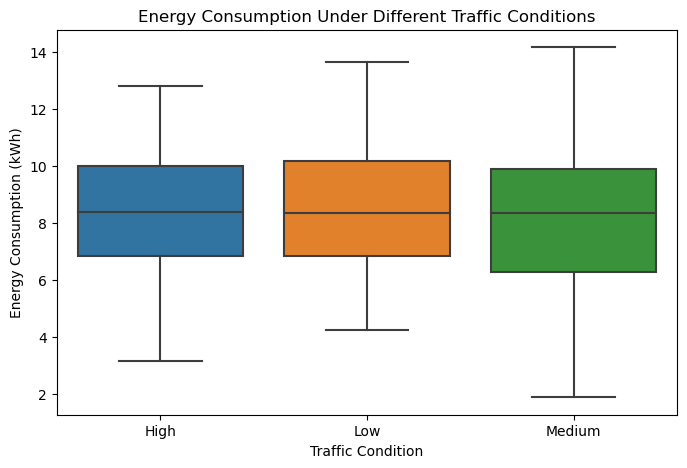

In [16]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_plot,
    x="Traffic_Condition",
    y="Energy_Consumption_Kwh"
)

plt.title("Energy Consumption Under Different Traffic Conditions")
plt.xlabel("Traffic Condition")
plt.ylabel("Energy Consumption (kWh)")

plt.show()

Does the same vehicle use different amounts of energy?

In [ ]:
top_vehicles = df["Vehicle_Id"].value_counts().head(10).index

vehicle_data = df[df["Vehicle_Id"].isin(top_vehicles)]

plt.figure(figsize=(10,6))

sns.boxplot(
    data=vehicle_data,
    x="Vehicle_Id",
    y="Energy_Consumption_Kwh"
)

plt.title("Energy Consumption Variation Across Vehicles")
plt.xlabel("Vehicle ID")
plt.ylabel("Energy Consumption (kWh)")

plt.xticks(rotation=45)

plt.show()

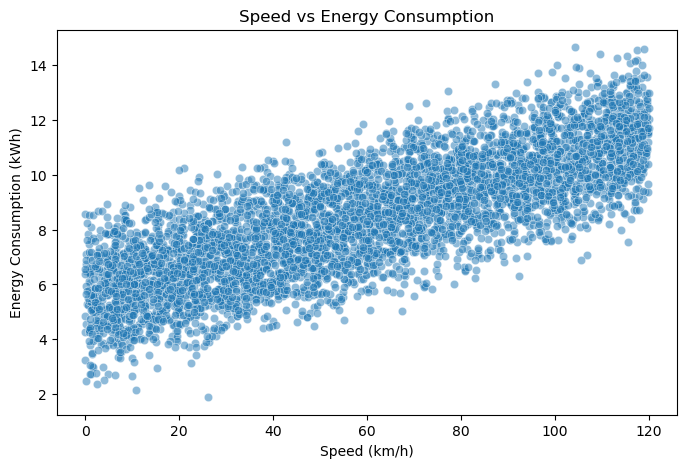

In [18]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Speed_Kmh",
    y="Energy_Consumption_Kwh",
    alpha=0.5
)

plt.title("Speed vs Energy Consumption")
plt.xlabel("Speed (km/h)")
plt.ylabel("Energy Consumption (kWh)")

plt.show()

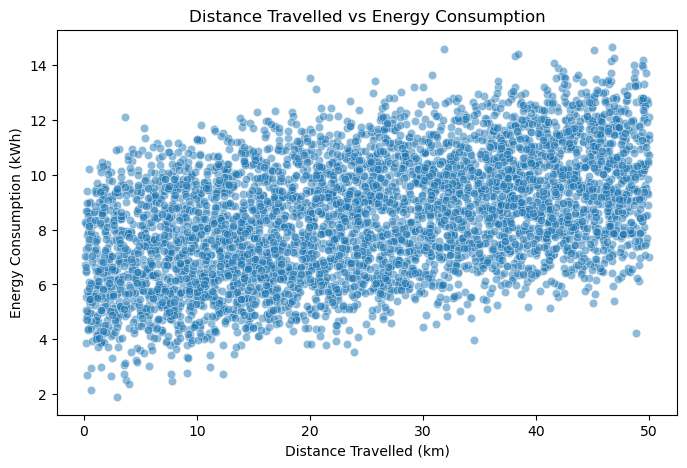

In [19]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Distance_Travelled_Km",
    y="Energy_Consumption_Kwh",
    alpha=0.5
)

plt.title("Distance Travelled vs Energy Consumption")
plt.xlabel("Distance Travelled (km)")
plt.ylabel("Energy Consumption (kWh)")

plt.show()

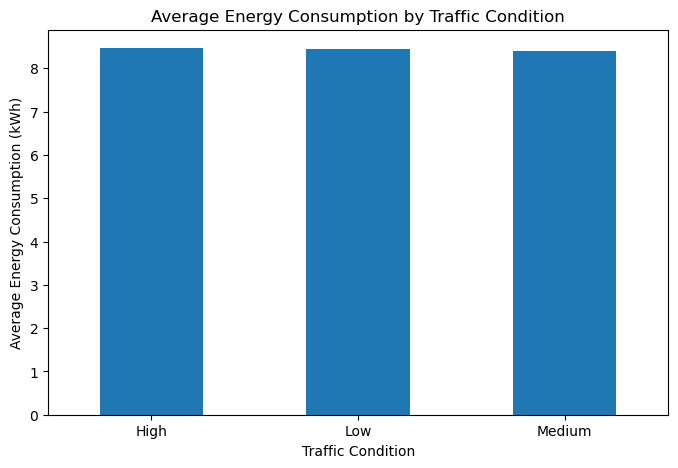

In [20]:
traffic_energy = df.groupby(
    "Traffic_Condition"
)["Energy_Consumption_Kwh"].mean()

plt.figure(figsize=(8,5))

traffic_energy.plot(kind="bar")

plt.title("Average Energy Consumption by Traffic Condition")
plt.xlabel("Traffic Condition")
plt.ylabel("Average Energy Consumption (kWh)")

plt.xticks(rotation=0)

plt.show()

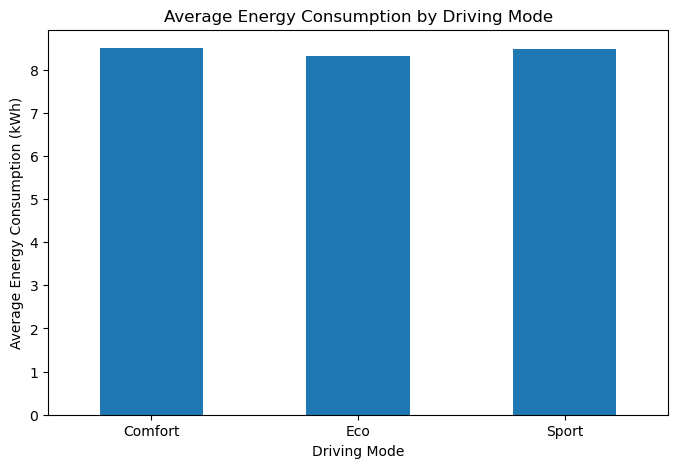

In [21]:
mode_energy = df.groupby(
    "Driving_Mode"
)["Energy_Consumption_Kwh"].mean()

plt.figure(figsize=(8,5))

mode_energy.plot(kind="bar")

plt.title("Average Energy Consumption by Driving Mode")
plt.xlabel("Driving Mode")
plt.ylabel("Average Energy Consumption (kWh)")

plt.xticks(rotation=0)

plt.show()

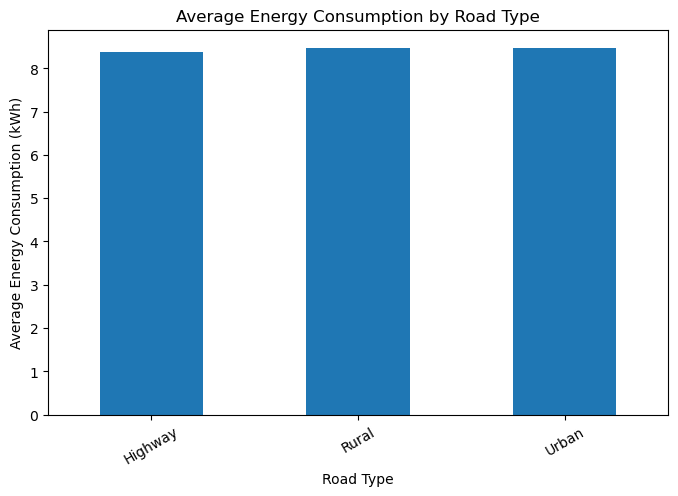

In [22]:
road_energy = df.groupby(
    "Road_Type"
)["Energy_Consumption_Kwh"].mean()

plt.figure(figsize=(8,5))

road_energy.plot(kind="bar")

plt.title("Average Energy Consumption by Road Type")
plt.xlabel("Road Type")
plt.ylabel("Average Energy Consumption (kWh)")

plt.xticks(rotation=30)

plt.show()

Do weather and temperature affect energy consumption?

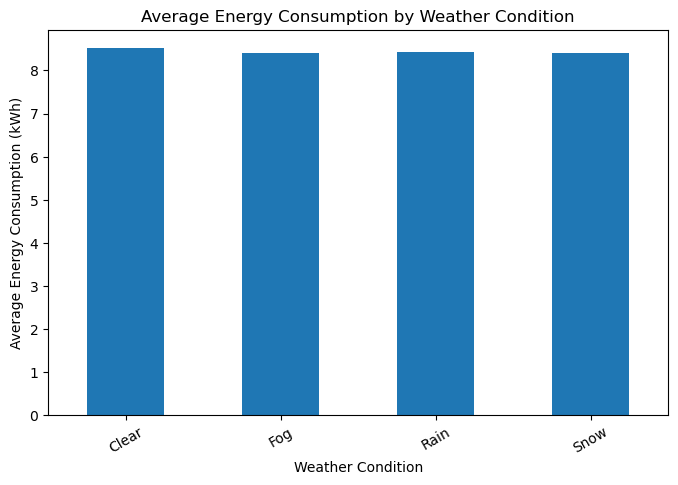

In [28]:
weather_energy = df.groupby(
    "Weather_Condition"
)["Energy_Consumption_Kwh"].mean()

plt.figure(figsize=(8,5))

weather_energy.plot(kind="bar")

plt.title("Average Energy Consumption by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Energy Consumption (kWh)")

plt.xticks(rotation=30)

plt.show()

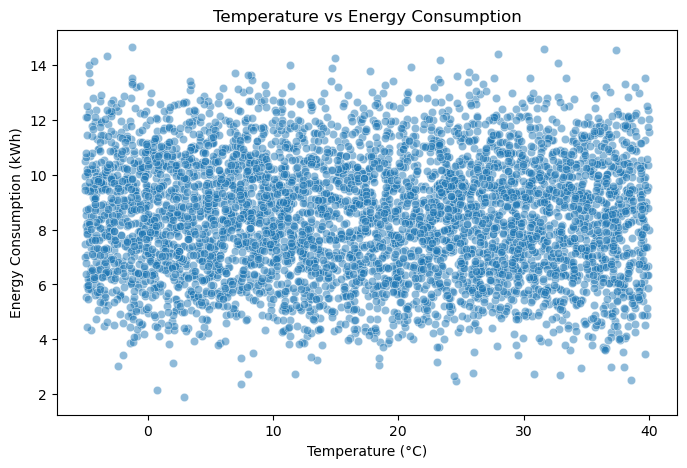

In [26]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Temperature_C",
    y="Energy_Consumption_Kwh",
    alpha=0.5
)

plt.title("Temperature vs Energy Consumption")
plt.xlabel("Temperature (°C)")
plt.ylabel("Energy Consumption (kWh)")

plt.show()

# Regression

In [15]:
X = df.drop(columns=['Energy_Consumption_Kwh','Vehicle_Id', 'Timestamp']).values
y = df['Energy_Consumption_Kwh'].values

n_features = X.shape[1]

from sklearn.model_selection import train_test_split
# Split into train and test datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [16]:
n_features = X.shape[1]
print(n_features)

16


In [17]:
# Define the model
model = Sequential()#4input 8 neurons in hidden
model.add(Dense(32, activation='relu', input_shape=(n_features,))) #1024 
model.add(Dense(32, activation='relu')) #1024 
#model.add(Dense(8, activation='relu')) #1024 
model.add(Dense(1))  # Single output neuron for regression (predicting price)
#no acitivation function in output layer
# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error') # lbfgs error 


In [18]:
#X_train = np.array(X_train, dtype=np.float32)
#y_train = np.array(y_train, dtype=np.float32)

model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=2)

ValueError: Failed to convert a NumPy array to a Tensor (Unsupported object type float).

In [ ]:
# Evaluate the model
loss = model.evaluate(X_test, y_test, verbose=0)
print('Test Mean Squared Error: %.2f' % loss)

Test Mean Squared Error: 0.54


In [ ]:
y_pred=model.predict(X_test)

52/52 [==============================] - 0s 3ms/step


In [ ]:
from sklearn.metrics import r2_score

score = r2_score( y_test,y_pred) #predicted y vs actual y
print("The accuracy of our model is {}%".format(round(score, 2) *100))


The accuracy of our model is 89.0%
